**Curso:** Procesamiento de Datos a Gran Escala

**Proyecto:** Consultoría Nueva York · Entrega final: preparación de datos, modelado y presentación de resultados

**Nombre del fichero:** `07_Modelado_Pobreza.ipynb`

**Tema:** Modelo de clasificación supervisado con Spark MLlib para identificar los perfiles de la población de Nueva York asociados a vivir en pobreza (año 2018).

**Objetivos:**
1. Seleccionar y justificar una técnica de aprendizaje supervisado de MLlib en función del objetivo de negocio.
2. Calcular correlaciones y eliminar variables fuertemente correlacionadas.
3. Normalizar las variables numéricas y describir el conjunto final de variables según criterio de negocio.
4. Aplicar los modelos sobre el cluster Spark del equipo consultor.
5. Evaluar los modelos con métricas adecuadas a un problema desbalanceado y con diferentes parámetros.
6. Presentar conclusiones conectadas con el objetivo de la consultoría.

# Contenido y relación con la rúbrica de la entrega final

| Sección del cuaderno | Apartado de la entrega |
|---|---|
| 0. Entorno y sesión Spark | Infraestructura (cluster) |
| 1. Carga de la tabla de pobreza | Entendimiento de los datos |
| 2. Filtros y transformaciones | 1. Filtros (≥ 2) y transformaciones (≥ 3) con justificación |
| 3. Selección de la técnica | 3. Técnica de aprendizaje supervisado con MLlib y su justificación |
| 4.1 Correlación | 4.a Eliminación de variables fuertemente correlacionadas |
| 4.2 Normalización | 4.b Normalización de variables numéricas |
| 4.3 Variables finales | 4.c Selección de variables según criterio de negocio |
| 5. Aplicación en el cluster | 5. Aplicación de las técnicas con MLlib |
| 6. Evaluación y análisis de resultados | 6. Evaluación con diferentes parámetros (hiperparámetros y umbral de decisión) |
| 7. Conclusiones | Cierre y conexión con el negocio |

> **Alcance del cuaderno.** Este cuaderno cubre la técnica **supervisada** (sobre la tabla de pobreza). La técnica **no supervisada** (K-Means sobre los arrestos) se desarrolla en el cuaderno de arrestos del equipo.

# Análisis de la primera ejecución y ajustes de esta versión

La primera ejecución en el cluster (validación cruzada) dejó resultados útiles y cuatro puntos por corregir. Esta versión los incorpora y completa la evaluación en prueba, que en esa ejecución no llegó a correr.

| Observación de la primera ejecución | Diagnóstico | Ajuste en esta versión |
|---|---|---|
| Los 3 filtros eliminaron **0 filas** | Los filtros no tenían efecto que justificar | El filtro 3 pasa a `AGEP >= 18`: el modelo describe a la población adulta, para la que las variables laborales sí aplican |
| `TotalWorkHrs_PU` tuvo r = **+0,40** con la pobreza, mientras `WKHP` (también horas) tuvo r = −0,23 | Signos opuestos para variables de "horas" indican que `TotalWorkHrs_PU` es un **código** (valores 1, 2, ... en la muestra), no una cantidad | Se trata como **categórica** (one-hot) |
| 74 características en el vector pero 63 nombres | `OneHotEncoder` con `handleInvalid="keep"` añadía una columna extra por variable categórica | Se quita esa opción: las importancias salen con nombres reales |
| Random Forest: AUC-ROC de validación **0,844** (profundidad 10, 50 árboles); 0,842 (10, 20); 0,818 (5, 20); 0,816 (5, 50) | La profundidad pesa (+0,026) y el número de árboles casi no (+0,002); el mejor valor quedó **en el borde de la grilla** | Se agrega `maxDepth = 15` (6 combinaciones) |
| Árbol de decisión: mejor AUC-ROC **0,749** (profundidad 8, gini); con profundidad 12 baja a 0,688 | Sobreajuste con árboles profundos; el bosque supera al árbol en ≈ 0,095, lo que justifica el ensamble | Sin cambio; queda como referencia |
| Regresión logística, prueba, matriz e importancias sin salida | El cuaderno se guardó antes de terminar | Se ejecutan en esta versión; se agregan análisis de umbral y texto automático de resultados |

Además se incorporan tres variables categóricas descriptivas (`ENG`, `HHT`, `JWTR`) y se corrige la sesión Spark para el error `Wrong FS` del cluster.

# 0. Entorno y sesión Spark

## 0.1 Librerías
- **PySpark** viene instalado en el kernel (`jupyter_env`, Python 3.11); no hace falta `findspark`. Si el `import pyspark` falla, se instala con `%pip install pyspark` y se reinicia el kernel.
- **`pyspark.ml`** es MLlib: transformadores de variables (`StringIndexer`, `OneHotEncoder`, `VectorAssembler`, `StandardScaler`), clasificadores (`DecisionTreeClassifier`, `RandomForestClassifier`, `LogisticRegression`), evaluadores y validación cruzada (`CrossValidator`).
- **`pandas`, `seaborn`, `matplotlib`** solo se usan para tablas pequeñas y gráficas con resultados ya agregados.

In [1]:
# QUÉ HACE: importa todas las librerías del cuaderno (datos, gráficas, Spark y MLlib).
# POR QUÉ: este kernel (jupyter_env) ya trae PySpark instalado con pip, por eso no se usa findspark.
import sys, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import pyspark
from pyspark import SparkConf
from pyspark.sql import SparkSession
from pyspark.sql import functions as F                      # F.col, F.when, F.expr ...

from pyspark.ml import Pipeline
from pyspark.ml.stat import Correlation                      # matriz de correlación
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import DecisionTreeClassifier, RandomForestClassifier, LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

print("Python:", sys.version.split()[0], "| PySpark:", pyspark.__version__)
print("Ejecutable:", sys.executable)

Python: 3.11.13 | PySpark: 4.2.0
Ejecutable: /home/estudiante/jupyter_env/bin/python3.11




## 0.2 Sesión Spark
`SparkSession.builder.config(...).getOrCreate()` abre la conexión con el cluster. El puerto `spark.ui.port` es propio de cada integrante para no chocar con otras sesiones. Si ya existe una sesión activa en el kernel, `getOrCreate()` la reutiliza.



In [2]:
# QUÉ HACE: abre (o reutiliza) la sesión Spark con un puerto de interfaz propio.
# POR QUÉ: getOrCreate() no crea una segunda sesión si ya existe una activa en este kernel.
configura = SparkConf().set("spark.ui.port", "37008")        # puerto propio de la Spark UI
configura.setAppName("ModeladoPobreza_Delgado")              # nombre visible en el Master (:8081)

# CORRECCIÓN: la configuración por defecto del cluster trae la ruta del planificador mal escrita
# (file://opt/...) y Spark falla con "Wrong FS". Se usa planificación FIFO y la ruta bien escrita.
configura.set("spark.scheduler.mode", "FIFO")
configura.set("spark.scheduler.allocation.file", "file:///opt/cluster/spark/conf/fairscheduler.xml")

sparkDelgado = SparkSession.builder.config(conf=configura).getOrCreate()
sparkContextDelgado = sparkDelgado.sparkContext
sparkContextDelgado.setLogLevel("ERROR")                     # oculta avisos repetidos (p. ej. "Broadcasting large task binary")

print("Versión de Spark:", sparkDelgado.version)
print("Master:", sparkDelgado.sparkContext.master)
print("Aplicación:", sparkDelgado.sparkContext.appName)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Versión de Spark: 4.2.0
Master: spark://10.43.97.76:8888
Aplicación: ModeladoPobreza_Delgado


# 1. Carga de la tabla de pobreza

La tabla `Pobreza_NY.csv` contiene registros de **personas** (con su hogar `SERIALNO` y número de persona `SPORDER`) de la encuesta del NYCgov Poverty Measure 2018. Cada persona tiene un peso muestral `PWGTP`, características sociodemográficas, componentes de ingreso y la variable de interés `NYCgov_Pov_Stat` (1 = en pobreza, 2 = no).

Se leen **todas las columnas como texto** porque el archivo usa punto de miles y coma decimal (por ejemplo `9.765,2422`). La conversión a número se hace de forma controlada en la sección siguiente.

In [3]:
# QUÉ HACE: lee Pobreza_NY.csv con todas las columnas como texto.
# POR QUÉ: el archivo usa punto de miles y coma decimal (p. ej. "9.765,2422"); si Spark intentara
#          inferir el tipo, esas columnas quedarían mal. Se convierten a mano en el siguiente bloque.
RUTA_POBREZA = "file:///opt/cluster/Proyecto/Entrega_1/datasets/Pobreza_NY.csv"

dfPob = (sparkDelgado.read.format("csv")
         .option("header", "true")
         .load(RUTA_POBREZA))

print("Filas leídas:", dfPob.count())
print("Columnas:", len(dfPob.columns))
dfPob.groupBy("NYCgov_Pov_Stat").count().orderBy("NYCgov_Pov_Stat").show()

Filas leídas: 68273
Columnas: 61


[Stage 4:==============>                                            (1 + 3) / 4]

+---------------+-----+
|NYCgov_Pov_Stat|count|
+---------------+-----+
|              1|12113|
|              2|56160|
+---------------+-----+



**Resultado observado en la ejecución del equipo:**
- **68.273 filas** y **61 columnas** (todas de tipo `string`).
- Distribución de la variable objetivo `NYCgov_Pov_Stat`: **12.113 personas en pobreza (1)** y **56.160 no (2)**. Es decir, **17,74 %** de registros positivos: el problema está **desbalanceado** (aproximadamente 4,6 personas sin pobreza por cada una en pobreza).

> **Qué implica el desbalance:** un modelo que respondiera siempre "no pobreza" tendría una exactitud de ≈ 82,3 % sin aprender nada. Por eso la evaluación (sección 6) usa AUC-ROC, AUC-PR, precisión y *recall* de la clase en pobreza, y no solo *accuracy*.

# 2. Filtros y transformaciones para el modelado

## 2.1 Definiciones previas
Se separan las variables candidatas en **numéricas** (o ordinales) y **categóricas** (códigos que no son cantidades) y se define `num_es`, que convierte el texto con formato español a número usando `try_cast` (si el valor no se puede convertir, devuelve `NULL` en lugar de provocar un error).

In [4]:
# QUÉ HACE: define las listas de variables candidatas y la función de conversión numérica.
# POR QUÉ: así el resto del cuaderno solo cambia estas listas si se decide agregar o quitar variables.

# Variables NUMÉRICAS (u ordinales) candidatas
NUM_CAND = ["AGEP", "AgeCateg", "WKHP", "NP", "EducAttain", "SCHL", "WKW"]

# Variables CATEGÓRICAS candidatas (los números son códigos, no cantidades)
# TotalWorkHrs_PU se trata como categórica: sus valores son códigos (1, 2, ...), no horas reales
CAT_CAND = ["SEX", "Boro", "CitizenStatus", "Ethnicity", "FamType_PU", "FTPTWork", "TotalWorkHrs_PU",
            "DIS", "ESR", "MAR", "LANX", "TEN", "ENG", "HHT", "JWTR"]

def num_es(nombre):
    """Convierte texto con formato español ('9.765,2422') a número.
    try_cast devuelve NULL (en vez de error) cuando el valor no se puede convertir."""
    return F.expr(f"try_cast(replace(replace(`{nombre}`, '.', ''), ',', '.') as double)")

## 2.2 Filtros (3)

| # | Filtro | Justificación |
|---|---|---|
| 1 | `PWGTP > 0` | El peso de persona indica cuánta población representa cada registro; un peso nulo o no positivo no representa a nadie y no debe entrenar el modelo. En la primera entrega se verificó que no había pesos inválidos; el filtro se deja como control de calidad. |
| 2 | `NYCgov_Pov_Stat` ∈ {1, 2} | La etiqueta debe ser válida; un registro sin estado de pobreza no puede ser ejemplo de entrenamiento ni de prueba. |
| 3 | `AGEP >= 18` (solo adultos) | El objetivo es describir el perfil de la población adulta. En menores la pobreza se hereda del hogar y las variables laborales (horas, semanas, situación laboral) no aplican, lo que mezclaría dos poblaciones distintas. Una edad nula tampoco pasa el filtro. |

Los filtros 1 y 2 son controles de calidad: la primera entrega ya verificó que no había pesos inválidos ni estados de pobreza desconocidos, así que se espera que eliminen 0 filas (en la primera ejecución lo confirmaron). El filtro 3 es el que cambia la población: elimina a los menores de 18 años.

In [5]:
# QUÉ HACE: aplica 3 filtros y deja la tabla con solo las columnas necesarias para el modelo.
# POR QUÉ: cada filtro elimina filas que no sirven para entrenar (ver justificación arriba).
base = dfPob.select(
    F.col("SERIALNO"),                                               # hogar (para dividir sin fuga)
    num_es("PWGTP").alias("PWGTP"),                                  # peso de persona
    num_es("NYCgov_Pov_Stat").alias("pov_stat"),                     # 1 = en pobreza, 2 = no
    *[num_es(c).alias(c) for c in NUM_CAND],
    *[F.coalesce(F.col(c), F.lit("NA")).alias(c) for c in CAT_CAND]  # nulo -> categoría "NA"
)

n0 = base.count()
f1 = base.filter(F.col("PWGTP") > 0)                          # FILTRO 1: peso válido (> 0)
n1 = f1.count()
f2 = f1.filter(F.col("pov_stat").isin(1.0, 2.0))              # FILTRO 2: estado de pobreza válido
n2 = f2.count()
f3 = f2.filter(F.col("AGEP") >= 18)                           # FILTRO 3: solo adultos (una edad nula tampoco pasa)
n3 = f3.count()

print(pd.DataFrame({
    "paso": ["Filas iniciales", "Filtro 1: PWGTP > 0", "Filtro 2: pov_stat en {1,2}", "Filtro 3: AGEP >= 18 (adultos)"],
    "filas": [n0, n1, n2, n3],
    "eliminadas": [0, n0 - n1, n1 - n2, n2 - n3]}).to_string(index=False))

                          paso  filas  eliminadas
               Filas iniciales  68273           0
           Filtro 1: PWGTP > 0  68273           0
   Filtro 2: pov_stat en {1,2}  68273           0
Filtro 3: AGEP >= 18 (adultos)  54926       13347


La tabla muestra cuántas filas había antes y cuántas elimina cada filtro. Los filtros 1 y 2 con 0 eliminadas son **evidencia de calidad** de los datos; las filas eliminadas por el filtro 3 son los menores de 18 años y se reportan en el documento.

## 2.3 Transformaciones (4)

| # | Transformación | Justificación |
|---|---|---|
| 1 | **Etiqueta binaria**: `etiqueta = 1` si `NYCgov_Pov_Stat = 1`, `0` si no | Los clasificadores de MLlib necesitan una etiqueta 0/1; así el "1" es la clase de interés (en pobreza). |
| 2 | **Nulos numéricos → 0** | En esta encuesta, un valor nulo en variables como horas trabajadas (`WKHP`) o semanas trabajadas (`WKW`) significa *no aplica* (personas sin trabajo), no *dato perdido*; el cero conserva ese significado. |
| 3 | **Peso de clase** `peso_clase` (= razón negativos/positivos para la clase en pobreza y 1 para la otra) | Compensa el desbalance durante el entrenamiento para que el modelo no ignore la clase minoritaria. |
| 4 | **Grupos por hogar** (`grupo_split` y `fold_cv`, a partir de `hash(SERIALNO)`) | Las personas de un mismo hogar comparten tamaño de hogar, vivienda y, sobre todo, el mismo estado de pobreza. Si una parte del hogar queda en entrenamiento y otra en prueba, el modelo "reconoce" al hogar y el resultado se infla (*fuga de información*). Asignar el hogar completo a un solo grupo evita esa fuga. |

Además, las categóricas con valor nulo se reemplazan por la categoría `"NA"` (ya aplicado en el bloque anterior).

In [6]:
# QUÉ HACE: crea la etiqueta, rellena nulos numéricos, calcula pesos de clase y el grupo por hogar.
# POR QUÉ: cada transformación prepara una pieza que el modelo necesita (ver justificación arriba).

# TRANSFORMACIÓN 1: etiqueta binaria (1 = en pobreza, 0 = no)
datos = f3.withColumn("etiqueta", F.when(F.col("pov_stat") == 1.0, 1.0).otherwise(0.0))

# TRANSFORMACIÓN 2: nulos numéricos -> 0 (corresponde a "no aplica": personas sin trabajo)
datos = datos.fillna(0.0, subset=NUM_CAND)

# TRANSFORMACIÓN 3: peso de clase para compensar el desbalance (pocos casos en pobreza)
n_pos = datos.filter("etiqueta = 1").count()
n_neg = datos.filter("etiqueta = 0").count()
RATIO = n_neg / n_pos
datos = datos.withColumn("peso_clase", F.when(F.col("etiqueta") == 1.0, F.lit(RATIO)).otherwise(F.lit(1.0)))

# TRANSFORMACIÓN 4: grupos por HOGAR (todas las personas de un hogar quedan en el mismo grupo)
datos = (datos
         .withColumn("grupo_split", F.expr("pmod(hash(SERIALNO), 5)"))        # 0..4 -> prueba = grupo 0
         .withColumn("fold_cv",     F.expr("pmod(hash(SERIALNO, 'cv'), 3)"))) # 0..2 -> validación cruzada

datos = datos.cache()
print("Filas del conjunto de modelado:", datos.count())
print(f"En pobreza: {n_pos} ({n_pos/(n_pos+n_neg):.2%})  |  No pobreza: {n_neg}  |  Peso de clase positiva: {RATIO:.2f}")
datos.groupBy("grupo_split").count().orderBy("grupo_split").show()

Filas del conjunto de modelado: 54926
En pobreza: 9410 (17.13%)  |  No pobreza: 45516  |  Peso de clase positiva: 4.84
+-----------+-----+
|grupo_split|count|
+-----------+-----+
|          0|11054|
|          1|10786|
|          2|10905|
|          3|11169|
|          4|11012|
+-----------+-----+




- Se imprime el número total de filas de modelado y el porcentaje en pobreza (puede diferir del 17,74 % de la sección 1, porque ahora solo quedan adultos).
- `Peso de clase positiva` es la razón entre personas sin pobreza y en pobreza (en la tabla completa era 4,64): cada persona en pobreza "pesa" ese número de veces más durante el entrenamiento.
- La tabla `grupo_split` muestra cuántas filas caen en cada uno de los 5 grupos de hogares. Se usa el **grupo 0 (≈ 20 %) como prueba** y los grupos 1 a 4 (≈ 80 %) como entrenamiento.

# 3. Selección de la técnica de aprendizaje supervisado

**Problema de negocio.** El objetivo de la consultoría es entregar al gobierno de Nueva York criterios basados en evidencia para focalizar acciones territoriales, y analizar cómo se relacionan las condiciones socioeconómicas con los indicadores de seguridad. La pregunta que responde este cuaderno es: **¿qué características de las personas y de sus hogares se asocian con vivir en pobreza, y con qué precisión se puede identificar ese perfil?**

**Técnica elegida: Random Forest (bosque aleatorio), con Árbol de Decisión y Regresión Logística como referencias.**

| Criterio | Por qué el bosque aleatorio responde bien |
|---|---|
| Tipo de problema | Clasificación binaria (en pobreza / no), con etiqueta disponible: aprendizaje **supervisado**. |
| Variables mixtas | Maneja variables numéricas y categóricas codificadas, sin exigir linealidad. |
| Relaciones no lineales e interacciones | Puede capturar combinaciones (edad × empleo × tipo de hogar) sin definirlas de antemano; la comparación con el modelo lineal (sección 6) muestra cuánto aportan en este caso. |
| Interpretabilidad para el negocio | Entrega **importancia de cada característica**, que permite traducir el modelo a perfiles de población. |
| Escala | Está implementado de forma distribuida en MLlib y entrena sobre las 68.273 filas en el cluster. |

**Modelos de referencia:** el **Árbol de Decisión** (simple e interpretable) y la **Regresión Logística** (lineal) sirven para comprobar si la complejidad del bosque aporta mejora real. Los tres se entrenan con varias combinaciones de parámetros (sección 5).

**Resultado de la comparación (sección 6).** En prueba, la Regresión Logística obtuvo AUC-ROC de 0,857 y el Random Forest de 0,851; la diferencia (0,006) es muy pequeña, de modo que la complejidad del bosque no mejora la predicción y la relación entre las variables y la pobreza es en gran parte lineal. Por eso el Random Forest se conserva como **modelo de interpretación** (importancia de características, sin supuestos sobre la forma de la relación) y la Regresión Logística como **control que lo iguala**. Ambos superan al Árbol de Decisión (0,803).

> **Coordinación con el equipo.** La técnica **no supervisada** del bloque (K-Means sobre arrestos) la desarrolla el cuaderno de arrestos; en el documento se redacta la justificación conjunta: el modelo supervisado explica *quién* está en pobreza y el no supervisado describe *dónde* se concentran los arrestos.

# 4. Preparación de datos para el modelado

## 4.1 Correlación entre variables numéricas (apartado 4.a)

La correlación de Pearson mide, entre −1 y 1, qué tan linealmente se mueven dos variables juntas. Si dos variables tienen |r| muy alto, **aportan casi la misma información**; mantener ambas no mejora el modelo y dificulta interpretar la importancia de cada una (la importancia se reparte entre ellas).

`Correlation.corr` de MLlib calcula la matriz de forma distribuida sobre un vector ensamblado con `VectorAssembler`; la matriz resultante (solo 7 × 7) se trae al *driver* para graficarla como mapa de calor.

Las candidatas son: `AGEP` (edad), `AgeCateg` (grupo de edad), `WKHP` (horas trabajadas por semana), `NP` (tamaño del hogar), `EducAttain` (nivel educativo en 4 categorías), `SCHL` (nivel educativo detallado) y `WKW` (semanas trabajadas en el año, en rangos). `TotalWorkHrs_PU` no entra aquí porque es un código y se trata como categórica.

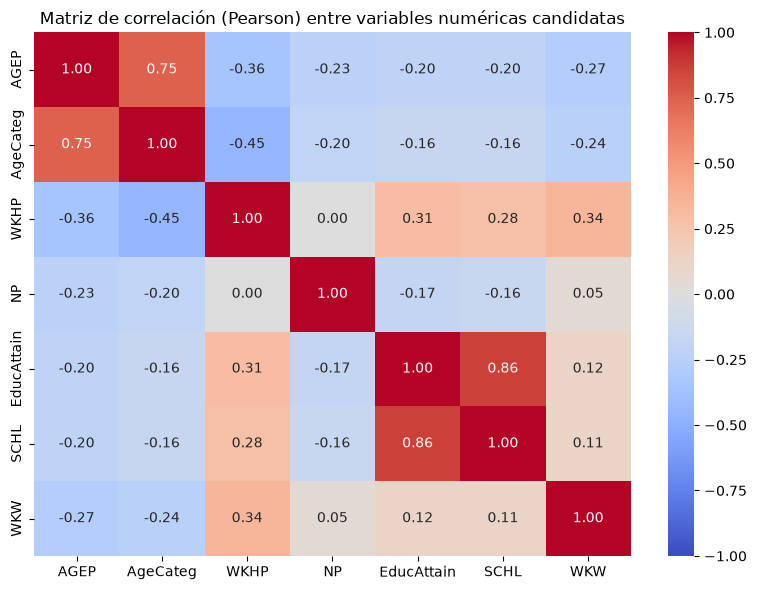

In [7]:
# QUÉ HACE: calcula la matriz de correlación de Pearson entre las variables numéricas candidatas.
# POR QUÉ: dos variables casi iguales (|r| alto) aportan lo mismo y confunden la interpretación.
asm_corr = VectorAssembler(inputCols=NUM_CAND, outputCol="vec_num", handleInvalid="keep")
vec = asm_corr.transform(datos).select("vec_num")

matriz = Correlation.corr(vec, "vec_num", "pearson").head()[0].toArray()
corr_pd = pd.DataFrame(matriz, index=NUM_CAND, columns=NUM_CAND)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_pd, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación (Pearson) entre variables numéricas candidatas")
plt.tight_layout()
plt.show()


### Regla para eliminar variables
Se fija el umbral **|r| > 0,80**. Para cada par que lo supera se **conserva la primera variable listada** y se elimina la segunda (se prefiere `AGEP` sobre `AgeCateg` porque conserva la edad exacta, y `EducAttain` sobre `SCHL` porque sus 4 categorías son más fáciles de interpretar para el negocio).

In [8]:
# QUÉ HACE: recorre los pares de variables y elimina la segunda de cada par con |r| > umbral.
# POR QUÉ: regla automática y reproducible: se conserva la primera variable listada en NUM_CAND.
UMBRAL = 0.80
eliminadas, detalle = [], []
for i, a in enumerate(NUM_CAND):
    for b in NUM_CAND[i + 1:]:
        if a in eliminadas or b in eliminadas:
            continue
        r = corr_pd.loc[a, b]
        if abs(r) > UMBRAL:
            eliminadas.append(b)
            detalle.append((a, b, round(float(r), 3)))

NUM_FINAL = [c for c in NUM_CAND if c not in eliminadas]
print("Pares con |r| >", UMBRAL, "(conserva, elimina, r):", detalle)
print("Variables numéricas eliminadas:", eliminadas)
print("Variables numéricas finales   :", NUM_FINAL)

# Correlación de cada variable numérica final con la etiqueta (referencia descriptiva)
print("\nCorrelación con la etiqueta (en pobreza = 1):")
for c in NUM_FINAL:
    print(f"  {c:18s} r = {datos.stat.corr(c, 'etiqueta'):+.3f}")

Pares con |r| > 0.8 (conserva, elimina, r): [('EducAttain', 'SCHL', 0.864)]
Variables numéricas eliminadas: ['SCHL']
Variables numéricas finales   : ['AGEP', 'AgeCateg', 'WKHP', 'NP', 'EducAttain', 'WKW']

Correlación con la etiqueta (en pobreza = 1):
  AGEP               r = +0.011
  AgeCateg           r = +0.033
  WKHP               r = -0.270
  NP                 r = -0.024
  EducAttain         r = -0.204
  WKW                r = -0.014



## 4.2 Normalización de variables numéricas (apartado 4.b)

Las variables numéricas tienen escalas muy distintas (edad de 0 a 99, horas de 0 a 99, tamaño del hogar de 1 a 20). Se **estandarizan** con `StandardScaler` (media 0 y desviación 1): `z = (x − media) / desviación`.

- **Por qué:** la Regresión Logística es sensible a la escala (una variable con valores grandes domina la penalización); además deja todas las numéricas comparables en un mismo vector.
- **Para el bosque y el árbol** la normalización no cambia los resultados (dividen por umbrales), pero se aplica igual para que los tres modelos reciban exactamente las mismas características.
- **Variables categóricas:** se convierten con `StringIndexer` (texto → índice) y `OneHotEncoder` (una columna 0/1 por categoría); no se normalizan.
- **Sin fuga de información:** el escalador y los indexadores se ajustan **solo con el entrenamiento** y se aplican igual a la prueba.

## 4.3 Variables finales según criterio de negocio (apartado 4.c)

**Criterio de negocio.** El modelo debe explicar la pobreza a partir de **características sociodemográficas observables** (quién es la persona y cómo es su hogar), que el gobierno puede usar para segmentar y focalizar políticas. No debe usar variables que **definan** la pobreza o la contengan.

**Variables que se excluyen y por qué:**

| Grupo | Columnas | Motivo |
|---|---|---|
| Resultado / definición de la pobreza | `NYCgov_Income`, `NYCgov_Threshold`, `EST_PovGap`, `EST_PovGapIndex`, `Off_Pov_Stat`, `Off_Threshold` | La pobreza se define comparando el ingreso con el umbral; incluirlas haría que el modelo "descubra" la fórmula y el AUC saldría casi perfecto sin aportar conocimiento. |
| Componentes de ingreso y beneficios | `EST_Childcare`, `EST_Commuting`, `EST_EITC`, `EST_FICAtax`, `EST_HEAP`, `EST_Housing`, `EST_IncomeTax`, `EST_MOOP`, `EST_Nutrition`, `INTP_adj`, `MRGP_adj`, `OI_adj`, `PA_adj`, `PreTaxIncome_PU`, `RETP_adj`, `RNTP_adj`, `SEMP_adj`, `SSIP_adj`, `SSP_adj`, `WAGP_adj` | Son partes del ingreso o gastos que se suman para decidir el estado de pobreza (misma fuga). |
| Identificadores y pesos | `SERIALNO`, `SPORDER`, `Povunit_ID`, `PWGTP`, `WGTP` | No tienen significado predictivo; el hogar se usa para dividir los datos y `PWGTP` para el control de calidad. |
| Redundantes | `CIT` (frente a `CitizenStatus`), `REL`, `NYCgov_REL`, `Povunit_Rel`, `SCH`, `SCHG`, `MSP` (frente a `MAR`) | Repiten información de otra variable ya incluida o son muy específicas con muchos nulos. |

**Grupo final de variables:**

| Tipo | Variables | Qué representan |
|---|---|---|
| Numéricas (tras eliminar correlacionadas) | las impresas en `NUM_FINAL` | Edad, horas de trabajo, tamaño del hogar, nivel educativo, semanas trabajadas |
| Categóricas | `SEX`, `Boro`, `CitizenStatus`, `Ethnicity`, `FamType_PU`, `FTPTWork`, `TotalWorkHrs_PU`, `DIS`, `ESR`, `MAR`, `LANX`, `TEN`, `ENG`, `HHT`, `JWTR` | Sexo, distrito, ciudadanía, grupo étnico, tipo de familia, tipo de jornada, horas de trabajo del núcleo (código), discapacidad, situación laboral, estado civil, idioma en casa, tenencia de vivienda, dominio del inglés, tipo de hogar, medio de transporte al trabajo |

> **Nota de alcance.** Variables como `Ethnicity` o `Boro` se incluyen para **describir** perfiles de riesgo; no implican causalidad ni deben usarse para decisiones individuales. El uso de variables protegidas requiere cautela y debe declararse en el documento como limitación.

# 5. Aplicación de los modelos en el cluster Spark

## 5.1 División entrenamiento / prueba y vector de características
- **Entrenamiento:** hogares de los grupos 1 a 4 (≈ 80 %). **Prueba:** hogares del grupo 0 (≈ 20 %), que el modelo no ve mientras se entrena ni mientras se eligen los parámetros.
- Se construye un **Pipeline** de preparación (indexadores → one-hot → ensamblado de numéricas → normalización → vector final `features`), se **ajusta con el entrenamiento** y se aplica a ambos conjuntos.
- `NOMBRES` guarda el nombre de cada posición del vector para poder interpretar las importancias.

In [9]:
# QUÉ HACE: divide en entrenamiento/prueba por hogar y construye el vector de características.
# POR QUÉ: el pipeline (índices -> one-hot -> ensamblado -> normalización) se ajusta SOLO con
#          entrenamiento y luego se aplica igual a prueba, para no filtrar información.
train = datos.filter("grupo_split <> 0")        # ~80 % de los hogares
test  = datos.filter("grupo_split = 0")         # ~20 % de los hogares
print("Filas  train:", train.count(), "| test:", test.count())

# Categóricas: texto -> índice -> one-hot (cada categoría una columna 0/1)
indexers = [StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in CAT_CAND]
ohe = OneHotEncoder(inputCols=[c + "_idx" for c in CAT_CAND],
                    outputCols=[c + "_ohe" for c in CAT_CAND],
                    dropLast=False)   # CORRECCIÓN: sin handleInvalid="keep" (el indexador ya reserva la categoría "otra")

# Numéricas: ensamblar -> normalizar (media 0, desviación 1)
asm_num = VectorAssembler(inputCols=NUM_FINAL, outputCol="num_vec")
scaler  = StandardScaler(inputCol="num_vec", outputCol="num_scaled", withMean=True, withStd=True)

# Vector final: numéricas normalizadas + todas las columnas one-hot
asm_final = VectorAssembler(inputCols=["num_scaled"] + [c + "_ohe" for c in CAT_CAND], outputCol="features")

prep = Pipeline(stages=indexers + [ohe, asm_num, scaler, asm_final]).fit(train)

cols_keep = ["SERIALNO", "etiqueta", "peso_clase", "PWGTP", "fold_cv", "features"]
train_p = prep.transform(train).select(*cols_keep).cache()
test_p  = prep.transform(test).select(*cols_keep).cache()

# Nombres de cada posición del vector (para interpretar importancias)
NOMBRES = list(NUM_FINAL)
for c, idx_model in zip(CAT_CAND, prep.stages[:len(CAT_CAND)]):
    NOMBRES += [f"{c}={lab}" for lab in idx_model.labelsArray[0]] + [f"{c}=otra"]
N_FEATURES = len(train_p.first()["features"])
print("Número de características:", N_FEATURES, "| nombres generados:", len(NOMBRES))
if len(NOMBRES) != N_FEATURES:        # protección: si no coinciden, se usan nombres genéricos
    print("AVISO: los nombres no coinciden con el vector; se usan nombres genéricos f0, f1, ...")
    NOMBRES = [f"f{i}" for i in range(N_FEATURES)]

Filas  train: 43872 | test: 11054


[Stage 155:>                                                        (0 + 1) / 1]

Número de características: 95 | nombres generados: 95



## 5.2 Funciones de evaluación
Se definen una vez las métricas que se aplicarán a todos los modelos:
- **AUC-ROC:** capacidad de separar las dos clases sin depender de un umbral (0,5 = azar; 1 = perfecto).
- **AUC-PR:** área bajo la curva precisión–*recall*; es **más informativa que el ROC cuando la clase positiva es minoritaria**.
- **Precisión (pobreza):** de los que el modelo dice "pobreza", ¿cuántos realmente lo están?
- **Recall (pobreza):** de los que realmente están en pobreza, ¿cuántos detecta el modelo?
- **F1:** media armónica de precisión y *recall*.
- **Accuracy:** porcentaje total de aciertos (engañosa con clases desbalanceadas; se muestra como referencia).

In [10]:
# QUÉ HACE: define las métricas y una función que evalúa cualquier modelo sobre un DataFrame.
# POR QUÉ: todos los modelos se comparan con las mismas métricas y sobre el mismo conjunto de prueba.
ev_roc = BinaryClassificationEvaluator(labelCol="etiqueta", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
ev_pr  = BinaryClassificationEvaluator(labelCol="etiqueta", rawPredictionCol="rawPrediction", metricName="areaUnderPR")

def evaluar(modelo, df, nombre):
    pred = modelo.transform(df).cache()
    cm = {(int(r["etiqueta"]), int(r["prediction"])): r["count"]
          for r in pred.groupBy("etiqueta", "prediction").count().collect()}
    tp, fn = cm.get((1, 1), 0), cm.get((1, 0), 0)
    fp, tn = cm.get((0, 1), 0), cm.get((0, 0), 0)
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec  = tp / (tp + fn) if (tp + fn) else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return {"modelo": nombre,
            "AUC_ROC": ev_roc.evaluate(pred), "AUC_PR": ev_pr.evaluate(pred),
            "accuracy": (tp + tn) / (tp + tn + fp + fn),
            "precision_pobreza": prec, "recall_pobreza": rec, "F1_pobreza": f1,
            "TP": tp, "FN": fn, "FP": fp, "TN": tn}

def tabla_cv(cv_model, grid, nombres_param):
    """Resumen de la validación cruzada: una fila por combinación de parámetros."""
    filas = []
    for pm, m in zip(grid, cv_model.avgMetrics):
        fila = {n: pm[p] for n, p in nombres_param.items()}
        fila["AUC_ROC_validacion"] = m
        filas.append(fila)
    return pd.DataFrame(filas).sort_values("AUC_ROC_validacion", ascending=False).reset_index(drop=True)

## 5.3 Random Forest con validación cruzada

**Parámetros que se prueban**
- `maxDepth` ∈ {5, 10, 15}: profundidad máxima de cada árbol (más profundo = más ajuste y riesgo de sobreajuste).
- `numTrees` ∈ {20, 50}: número de árboles del bosque (más árboles = resultado más estable pero más costo).

Son **6 combinaciones**, cada una evaluada con **validación cruzada de 3 pliegues** agrupados por hogar (`foldCol`) y se elige la de mayor AUC-ROC promedio. `weightCol="peso_clase"` aplica el peso de clase de la sección 2.

In [11]:
# QUÉ HACE: entrena el Random Forest probando 6 combinaciones de parámetros con validación cruzada.
# POR QUÉ: maxDepth y numTrees controlan la complejidad; CrossValidator elige la mejor combinación
#          según AUC-ROC en validación (3 pliegues agrupados por hogar con foldCol).
rf = RandomForestClassifier(labelCol="etiqueta", featuresCol="features", weightCol="peso_clase", seed=42)
grid_rf = (ParamGridBuilder()
           .addGrid(rf.maxDepth, [5, 10, 15])
           .addGrid(rf.numTrees, [20, 50])
           .build())
cv_rf = CrossValidator(estimator=rf, estimatorParamMaps=grid_rf, evaluator=ev_roc,
                       numFolds=3, foldCol="fold_cv", seed=42)
cvm_rf = cv_rf.fit(train_p)
mejor_rf = cvm_rf.bestModel

display_rf = tabla_cv(cvm_rf, grid_rf, {"maxDepth": rf.maxDepth, "numTrees": rf.numTrees})
print(display_rf.to_string(index=False))
print("\nMejor Random Forest -> maxDepth =", mejor_rf.getMaxDepth(), "| numTrees =", mejor_rf.getNumTrees)

26/11/17 08:53:55 ERROR TaskSchedulerImpl: Lost executor 0 on 10.43.97.66: Command exited with code 137
                                                                                

 maxDepth  numTrees  AUC_ROC_validacion
       10        50            0.852330
       15        50            0.849813
       10        20            0.849323
       15        20            0.845047
        5        50            0.830415
        5        20            0.824898

Mejor Random Forest -> maxDepth = 10 | numTrees = 50



## 5.4 Árbol de decisión con validación cruzada
Parámetros: `maxDepth` ∈ {3, 5, 8, 12} e `impurity` ∈ {gini, entropy} (criterio con que cada nodo elige su división): **8 combinaciones**.

In [12]:
# QUÉ HACE: entrena el Árbol de Decisión probando 8 combinaciones (profundidad x criterio).
# POR QUÉ: es el modelo base, simple e interpretable, contra el que se compara el bosque.
dt = DecisionTreeClassifier(labelCol="etiqueta", featuresCol="features", weightCol="peso_clase", seed=42)
grid_dt = (ParamGridBuilder()
           .addGrid(dt.maxDepth, [3, 5, 8, 12])
           .addGrid(dt.impurity, ["gini", "entropy"])
           .build())
cv_dt = CrossValidator(estimator=dt, estimatorParamMaps=grid_dt, evaluator=ev_roc,
                       numFolds=3, foldCol="fold_cv", seed=42)
cvm_dt = cv_dt.fit(train_p)
mejor_dt = cvm_dt.bestModel

print(tabla_cv(cvm_dt, grid_dt, {"maxDepth": dt.maxDepth, "impurity": dt.impurity}).to_string(index=False))
print("\nMejor Árbol -> maxDepth =", mejor_dt.getMaxDepth(), "| impureza =", mejor_dt.getImpurity())

 maxDepth impurity  AUC_ROC_validacion
        8  entropy            0.796834
        8     gini            0.793326
        5  entropy            0.771768
       12  entropy            0.761559
        5     gini            0.756122
       12     gini            0.752675
        3     gini            0.742201
        3  entropy            0.742201

Mejor Árbol -> maxDepth = 8 | impureza = entropy



## 5.5 Regresión logística (referencia lineal)
Parámetros: `regParam` ∈ {0, 0,01, 0,1} (intensidad de la regularización) y `elasticNetParam` ∈ {0, 1} (0 = penalización L2, 1 = penalización L1): **6 combinaciones**.

In [13]:
# QUÉ HACE: entrena la Regresión Logística (referencia lineal) con 6 combinaciones de regularización.
# POR QUÉ: sirve de comparación; si el bosque no supera a un modelo lineal, la complejidad no se justifica.
lr = LogisticRegression(labelCol="etiqueta", featuresCol="features", weightCol="peso_clase", maxIter=100)
grid_lr = (ParamGridBuilder()
           .addGrid(lr.regParam, [0.0, 0.01, 0.1])
           .addGrid(lr.elasticNetParam, [0.0, 1.0])
           .build())
cv_lr = CrossValidator(estimator=lr, estimatorParamMaps=grid_lr, evaluator=ev_roc,
                       numFolds=3, foldCol="fold_cv", seed=42)
cvm_lr = cv_lr.fit(train_p)
mejor_lr = cvm_lr.bestModel

print(tabla_cv(cvm_lr, grid_lr, {"regParam": lr.regParam, "elasticNetParam": lr.elasticNetParam}).to_string(index=False))
print("\nMejor Regresión Logística -> regParam =", mejor_lr.getRegParam(), "| elasticNetParam =", mejor_lr.getElasticNetParam())

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
                                                                                

 regParam  elasticNetParam  AUC_ROC_validacion
     0.00              0.0            0.857825
     0.00              1.0            0.857824
     0.01              0.0            0.857468
     0.01              1.0            0.855205
     0.10              0.0            0.849783
     0.10              1.0            0.793348

Mejor Regresión Logística -> regParam = 0.0 | elasticNetParam = 0.0


El mejor valor fue `regParam = 0` (AUC-ROC de validación 0,858) y la penalización L1 fuerte (`regParam = 0,1`) lo hundió a 0,793, porque elimina características útiles.

# 6. Evaluación de los modelos

## 6.1 Comparación en el conjunto de prueba
Cada mejor modelo (el elegido en validación cruzada) se evalúa **una sola vez** sobre los hogares de prueba. Se incluye una **línea base** ("siempre no pobreza") para mostrar por qué la *accuracy* no basta.

                     AUC_ROC  AUC_PR  accuracy  precision_pobreza  recall_pobreza  F1_pobreza
modelo                                                                                       
Random Forest         0.8509  0.5931    0.7869             0.4493          0.7395      0.5590
Árbol de Decisión     0.8026  0.4849    0.7404             0.3947          0.7900      0.5264
Regresión Logística   0.8571  0.6085    0.7810             0.4422          0.7623      0.5597

Línea base 'siempre no pobreza': accuracy = 0.8174, recall = 0.0000


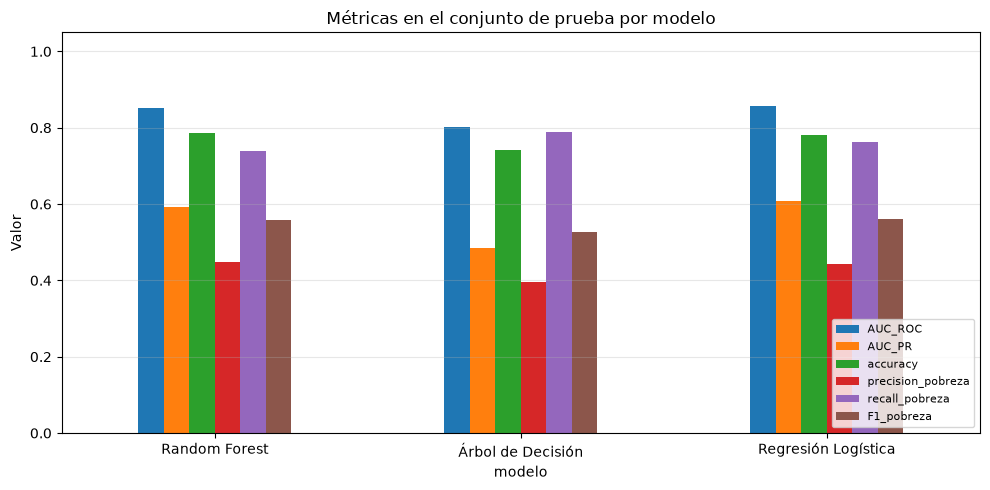

In [14]:
# QUÉ HACE: evalúa los tres mejores modelos sobre el conjunto de PRUEBA (hogares nunca vistos).
# POR QUÉ: la validación cruzada eligió los parámetros; la prueba da la medida honesta de desempeño.
resultados = pd.DataFrame([
    evaluar(mejor_rf, test_p, "Random Forest"),
    evaluar(mejor_dt, test_p, "Árbol de Decisión"),
    evaluar(mejor_lr, test_p, "Regresión Logística"),
]).set_index("modelo")

cols_metr = ["AUC_ROC", "AUC_PR", "accuracy", "precision_pobreza", "recall_pobreza", "F1_pobreza"]
print(resultados[cols_metr].round(4).to_string())

# Línea base: un modelo que siempre dice "no pobreza" (para mostrar por qué accuracy engaña)
n_test = test_p.count()
n_test_pos = test_p.filter("etiqueta = 1").count()
print(f"\nLínea base 'siempre no pobreza': accuracy = {1 - n_test_pos / n_test:.4f}, recall = 0.0000")

resultados[cols_metr].round(4).plot(kind="bar", figsize=(10, 5))
plt.title("Métricas en el conjunto de prueba por modelo")
plt.ylabel("Valor"); plt.xticks(rotation=0); plt.ylim(0, 1.05); plt.grid(axis="y", alpha=.3)
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()


## 6.2 Matriz de confusión del mejor modelo
La matriz cruza lo real con lo predicho:

|  | Predicho: no pobreza | Predicho: pobreza |
|---|---|---|
| **Real: no pobreza** | Verdaderos negativos (TN) | Falsos positivos (FP) |
| **Real: pobreza** | Falsos negativos (FN) | Verdaderos positivos (TP) |

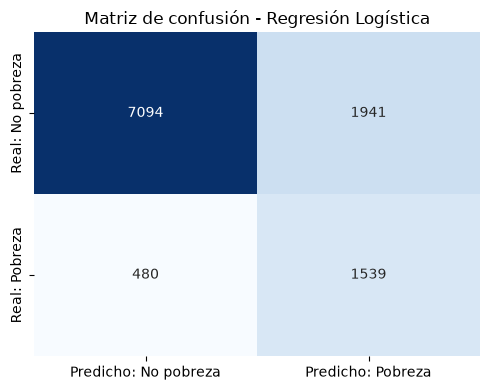

Mejor modelo por AUC-ROC en prueba: Regresión Logística


In [15]:
# QUÉ HACE: muestra la matriz de confusión del mejor modelo según AUC-ROC en prueba.
# POR QUÉ: permite ver cuántos hogares en pobreza se detectan (TP) y cuántos se pierden (FN).
mejor_nombre = resultados["AUC_ROC"].idxmax()
fila = resultados.loc[mejor_nombre]
mc = np.array([[fila["TN"], fila["FP"]], [fila["FN"], fila["TP"]]])

plt.figure(figsize=(5, 4))
sns.heatmap(mc, annot=True, fmt=".0f", cmap="Blues", cbar=False,
            xticklabels=["Predicho: No pobreza", "Predicho: Pobreza"],
            yticklabels=["Real: No pobreza", "Real: Pobreza"])
plt.title(f"Matriz de confusión - {mejor_nombre}")
plt.tight_layout(); plt.show()
print("Mejor modelo por AUC-ROC en prueba:", mejor_nombre)

**Cómo leer el resultado:** los **FN** (personas en pobreza que el modelo no detecta) son el error más costoso para una política de focalización; los **FP** son personas señaladas sin estar en pobreza. La proporción entre ambos depende del peso de clase usado y del umbral de decisión (0,5 por defecto).

## 6.3 Importancia de las características (Random Forest)
`featureImportances` indica cuánto contribuyó cada característica a reducir el error en el conjunto de árboles (suma 1). Como las categóricas están en *one-hot*, cada categoría aparece como `Variable=valor` (por ejemplo `FamType_PU=1`).

   caracteristica  importancia
TotalWorkHrs_PU=1     0.147001
             WKHP     0.086447
TotalWorkHrs_PU=4     0.071946
TotalWorkHrs_PU=5     0.057553
       FTPTWork=1     0.050443
              WKW     0.043336
       EducAttain     0.042419
            ESR=1     0.041309
            TEN=3     0.038731
             AGEP     0.029752
            TEN=2     0.028774
          JWTR=NA     0.026656
TotalWorkHrs_PU=3     0.021019
       FTPTWork=2     0.020580
               NP     0.019924


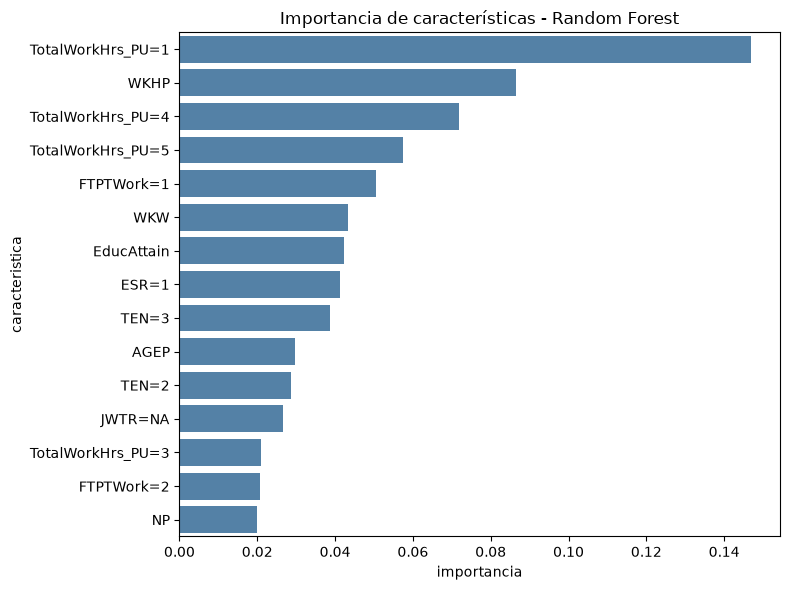

In [16]:
# QUÉ HACE: lista las 15 características más importantes del Random Forest.
# POR QUÉ: traduce el modelo a perfiles de población (qué rasgos se asocian a la pobreza).
imp = mejor_rf.featureImportances.toArray()
imp_pd = (pd.DataFrame({"caracteristica": NOMBRES[:len(imp)], "importancia": imp})
          .sort_values("importancia", ascending=False).head(15))
print(imp_pd.to_string(index=False))

plt.figure(figsize=(8, 6))
sns.barplot(data=imp_pd, y="caracteristica", x="importancia", color="steelblue")
plt.title("Importancia de características - Random Forest")
plt.tight_layout(); plt.show()

**Cómo leer el resultado:** las barras más largas son las características con más peso en la predicción. Importancia alta **no** indica la dirección del efecto (si aumenta o reduce la pobreza) ni causalidad; la dirección se interpreta comparando las tasas de pobreza por categoría (sección 6.4).

## 6.4 Tasa de pobreza por categoría
Para saber **en qué dirección** actúa cada característica importante se calcula la tasa observada de pobreza en cada categoría (sin ponderar y ponderada por `PWGTP`) para las variables de mayor importancia: horas de trabajo del núcleo (`TotalWorkHrs_PU`), tipo de jornada (`FTPTWork`), situación laboral (`ESR`), tenencia de vivienda (`TEN`) y nivel educativo (`EducAttain`). No se usan los coeficientes de la regresión logística porque, con el one-hot completo y sin regularización, no tienen un nivel de referencia único.

/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)



TotalWorkHrs_PU  (tasa global sin ponderar = 17.1%)
TotalWorkHrs_PU  personas  tasa_pobreza  tasa_ponderada
              1     20766        0.0406          0.0428
              2      7462        0.1072          0.1043
              3     11985        0.1279          0.1364
              4      6066        0.4088          0.4202
              5      8647        0.4341          0.4798


/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)



FTPTWork  (tasa global sin ponderar = 17.1%)
FTPTWork  personas  tasa_pobreza  tasa_ponderada
       1     24546        0.0574          0.0632
       2     12070        0.2100          0.2187
       3     18310        0.2985          0.3337


/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)



ESR  (tasa global sin ponderar = 17.1%)
ESR  personas  tasa_pobreza  tasa_ponderada
  1     33175        0.0980          0.1021
  2       861        0.1463          0.1456
  3      1896        0.3244          0.3433
  4        21        0.0476          0.0377
  6     18973        0.2855          0.3196


/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)



TEN  (tasa global sin ponderar = 17.1%)
TEN  personas  tasa_pobreza  tasa_ponderada
  1     14687        0.1024          0.1068
  2     10013        0.0950          0.0940
  3     29344        0.2304          0.2347
  4       882        0.2200          0.2064


/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/estudiante/jupyter_env/lib64/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)



EducAttain  (tasa global sin ponderar = 17.1%)
EducAttain  personas  tasa_pobreza  tasa_ponderada
       1.0      8630        0.3088          0.3309
       2.0     12453        0.2146          0.2239
       3.0     12123        0.1749          0.1869
       4.0     21720        0.0899          0.0964


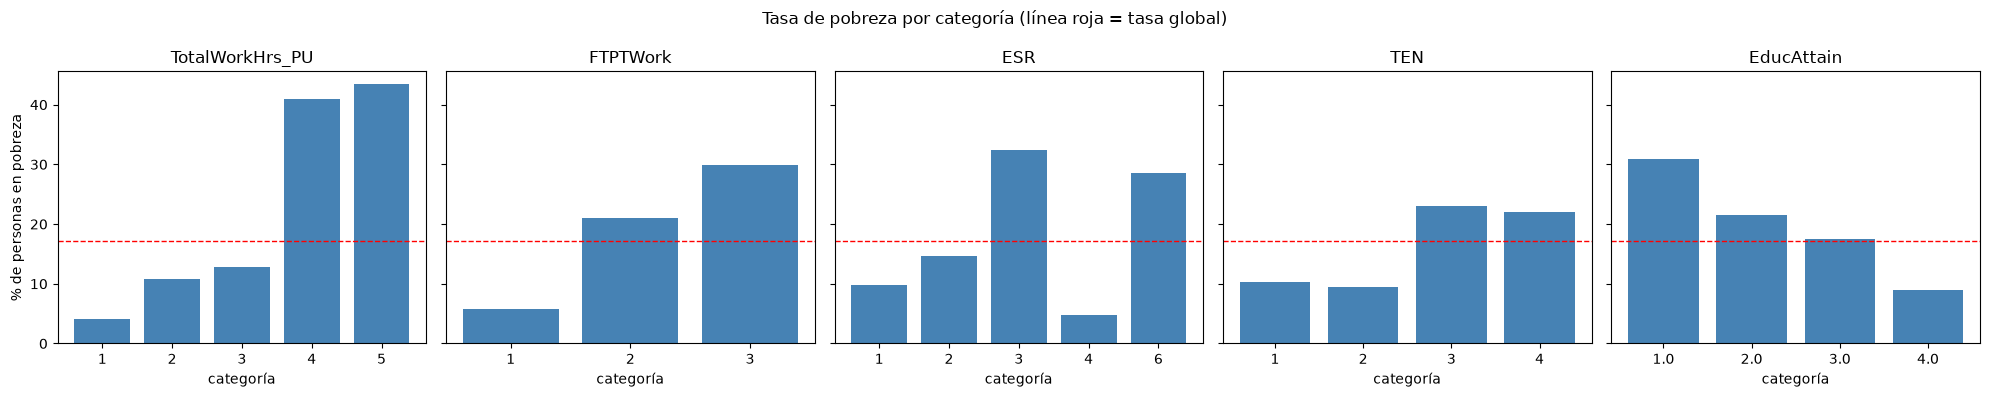

In [17]:
# QUÉ HACE: calcula la tasa de pobreza por categoría de las variables más importantes y la grafica.
# POR QUÉ: la importancia del bosque no dice si una categoría sube o baja la pobreza; la tasa observada sí.
#          (No se usan los coeficientes de la regresión logística porque el one-hot completo sin regularización
#          deja los coeficientes sin una escala única de referencia.)
VARS_PERFIL = ["TotalWorkHrs_PU", "FTPTWork", "ESR", "TEN", "EducAttain"]
tasa_global = datos.agg(F.avg("etiqueta")).first()[0]
fig, axes = plt.subplots(1, len(VARS_PERFIL), figsize=(20, 4), sharey=True)
for ax, v in zip(axes, VARS_PERFIL):
    t = (datos.groupBy(v)
         .agg(F.count("*").alias("personas"),
              F.avg("etiqueta").alias("tasa_pobreza"),
              (F.sum(F.col("PWGTP") * F.col("etiqueta")) / F.sum("PWGTP")).alias("tasa_ponderada"))
         .orderBy(v).toPandas())
    t[v] = t[v].astype(str)
    print(f"\n{v}  (tasa global sin ponderar = {tasa_global:.1%})")
    print(t.round(4).to_string(index=False))
    ax.bar(t[v], t["tasa_pobreza"] * 100, color="steelblue")
    ax.axhline(tasa_global * 100, color="red", linestyle="--", linewidth=1)
    ax.set_title(v); ax.set_xlabel("categoría")
axes[0].set_ylabel("% de personas en pobreza")
plt.suptitle("Tasa de pobreza por categoría (línea roja = tasa global)")
plt.tight_layout(); plt.show()

**Cómo leer el resultado:** cada barra es el porcentaje de personas en pobreza dentro de una categoría; la línea roja es la tasa global. Las categorías por encima de la línea concentran más pobreza que el promedio. Los códigos se interpretan con el diccionario de datos NYCgov antes de nombrarlos en el documento.

## 6.5 Efecto del umbral de decisión
Un modelo de probabilidad clasifica como "pobreza" cuando la probabilidad supera un umbral (0,5 por defecto). Esta celda recalcula precisión, *recall* y F1 con umbrales de 0,3 a 0,7 sobre el mejor modelo. Es una segunda forma de evaluar con diferentes parámetros: no cambia el modelo, cambia la decisión que se toma con él.

Modelo: Regresión Logística
 umbral  precision_pobreza  recall_pobreza  F1_pobreza  personas_pobreza_no_detectadas_FN  falsas_alarmas_FP
    0.3             0.3349          0.9054      0.4889                                191               3631
    0.4             0.3887          0.8361      0.5307                                331               2655
    0.5             0.4422          0.7623      0.5597                                480               1941
    0.6             0.5027          0.6904      0.5818                                625               1379
    0.7             0.5621          0.5939      0.5776                                820                934

Umbral con mayor F1: 0.6


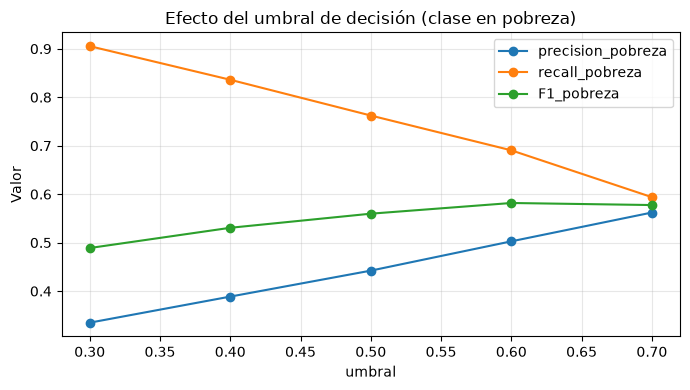

DataFrame[etiqueta: double, p: double]

In [18]:
# QUÉ HACE: recalcula precisión, recall y F1 de la clase en pobreza para distintos umbrales de decisión.
# POR QUÉ: por defecto un hogar se clasifica como "pobreza" si su probabilidad es >= 0,5; mover el umbral
#          cambia el equilibrio entre detectar más personas en pobreza (recall) y equivocarse menos (precisión).
from pyspark.ml.functions import vector_to_array

modelos_mejores = {"Random Forest": mejor_rf, "Árbol de Decisión": mejor_dt, "Regresión Logística": mejor_lr}
pp = (modelos_mejores[mejor_nombre].transform(test_p)
      .select("etiqueta", vector_to_array("probability")[1].alias("p")).cache())

UMBRALES = [0.3, 0.4, 0.5, 0.6, 0.7]
aggs = []
for t in UMBRALES:
    k = int(round(t * 100))
    pred1 = F.col("p") >= t
    aggs += [F.sum(F.when(pred1 & (F.col("etiqueta") == 1), 1).otherwise(0)).alias(f"tp_{k}"),
             F.sum(F.when(pred1 & (F.col("etiqueta") == 0), 1).otherwise(0)).alias(f"fp_{k}"),
             F.sum(F.when(~pred1 & (F.col("etiqueta") == 1), 1).otherwise(0)).alias(f"fn_{k}")]
r = pp.agg(*aggs).first()          # una sola pasada por los datos

filas = []
for t in UMBRALES:
    k = int(round(t * 100))
    tp, fp, fn = r[f"tp_{k}"], r[f"fp_{k}"], r[f"fn_{k}"]
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    filas.append({"umbral": t, "precision_pobreza": prec, "recall_pobreza": rec, "F1_pobreza": f1,
                  "personas_pobreza_no_detectadas_FN": fn, "falsas_alarmas_FP": fp})
umbral_pd = pd.DataFrame(filas)
print("Modelo:", mejor_nombre)
print(umbral_pd.round(4).to_string(index=False))

MEJOR_UMBRAL = float(umbral_pd.loc[umbral_pd["F1_pobreza"].idxmax(), "umbral"])
print(f"\nUmbral con mayor F1: {MEJOR_UMBRAL}")

ax = umbral_pd.set_index("umbral")[["precision_pobreza", "recall_pobreza", "F1_pobreza"]].plot(marker="o", figsize=(7, 4))
ax.set_title("Efecto del umbral de decisión (clase en pobreza)"); ax.set_ylabel("Valor"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
pp.unpersist()

**Cómo leer el resultado:** al bajar el umbral aumenta el *recall* (se detectan más personas en pobreza) y sube el número de falsas alarmas; al subirlo ocurre lo contrario. La elección depende del costo de cada error para la política pública. **Advertencia:** el umbral se explora sobre el conjunto de prueba, por lo que es un análisis de sensibilidad y no un umbral ya optimizado; para fijarlo de forma definitiva debería elegirse con validación.

## 6.6 Resumen numérico para el documento
Esta celda imprime las cifras reales de la ejecución y guarda un archivo `resultados_modelado_pobreza.json` con las métricas, las variables usadas y las más importantes.

In [19]:
# QUÉ HACE: imprime un resumen con los números REALES de esta ejecución y guarda un JSON.
# POR QUÉ: así el texto de las conclusiones puede copiarse con las cifras correctas.
mejor = resultados.loc[mejor_nombre]
print(f"Mejor modelo: {mejor_nombre}")
print(f"  AUC-ROC = {mejor['AUC_ROC']:.3f} | AUC-PR = {mejor['AUC_PR']:.3f} | accuracy = {mejor['accuracy']:.3f}")
print(f"  Precisión (pobreza) = {mejor['precision_pobreza']:.3f} | Recall (pobreza) = {mejor['recall_pobreza']:.3f} | F1 = {mejor['F1_pobreza']:.3f}")
print("Top 5 características (Random Forest):", ", ".join(imp_pd["caracteristica"].head(5)))

resumen = {"mejor_modelo": mejor_nombre,
           "metricas": resultados[cols_metr].round(4).to_dict(orient="index"),
           "top_caracteristicas": imp_pd.head(10).round(4).to_dict(orient="records"),
           "variables_numericas": NUM_FINAL, "variables_categoricas": CAT_CAND,
           "eliminadas_por_correlacion": eliminadas}
with open("resultados_modelado_pobreza.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2, default=float)
print("\nGuardado: resultados_modelado_pobreza.json (en la carpeta del cuaderno)")

Mejor modelo: Regresión Logística
  AUC-ROC = 0.857 | AUC-PR = 0.608 | accuracy = 0.781
  Precisión (pobreza) = 0.442 | Recall (pobreza) = 0.762 | F1 = 0.560
Top 5 características (Random Forest): TotalWorkHrs_PU=1, WKHP, TotalWorkHrs_PU=4, TotalWorkHrs_PU=5, FTPTWork=1

Guardado: resultados_modelado_pobreza.json (en la carpeta del cuaderno)


## 6.7 Análisis automático de resultados
Esta celda redacta, con las cifras reales de la ejecución, siete puntos de análisis: mejor modelo y comparación con las referencias, generalización (validación frente a prueba), detección de pobreza (*recall* y precisión), exactitud frente a la línea base, efecto del umbral, características más importantes y límites. El texto se guarda en `analisis_resultados_pobreza.txt` y se puede pegar directamente en el documento y en la presentación.

In [20]:
# QUÉ HACE: redacta automáticamente el análisis de resultados con las cifras reales de esta ejecución.
# POR QUÉ: así el texto del documento y de la presentación coincide exactamente con lo que calculó el cluster.
import textwrap

cv_auc = {"Random Forest": max(cvm_rf.avgMetrics), "Árbol de Decisión": max(cvm_dt.avgMetrics),
          "Regresión Logística": max(cvm_lr.avgMetrics)}
prev = n_test_pos / n_test                                  # proporción de pobreza en prueba
m = resultados.loc[mejor_nombre]
otros = resultados.drop(index=mejor_nombre)
rec, prec = m["recall_pobreza"], m["precision_pobreza"]
fn, fp, tp = int(m["FN"]), int(m["FP"]), int(m["TP"])
brecha = cv_auc[mejor_nombre] - m["AUC_ROC"]

L = []
L.append(f"1. Mejor modelo. En los hogares de prueba, {mejor_nombre} obtiene el mayor AUC-ROC ({m['AUC_ROC']:.3f}) y un "
         f"AUC-PR de {m['AUC_PR']:.3f}. Como la proporción de personas en pobreza en prueba es {prev:.1%}, un modelo al azar tendría "
         f"AUC-PR de {prev:.3f}: el modelo multiplica por {m['AUC_PR']/prev:.1f} la capacidad de acertar frente al azar.")
for nom, fila in otros.iterrows():
    L.append(f"   - Frente a {nom}: AUC-ROC {fila['AUC_ROC']:.3f} (diferencia de {m['AUC_ROC']-fila['AUC_ROC']:+.3f} a favor del mejor).")
if "Regresión Logística" in otros.index and mejor_nombre != "Regresión Logística":
    d_lr = m["AUC_ROC"] - otros.loc["Regresión Logística", "AUC_ROC"]
    L.append("   Lectura: " + ("la regresión logística queda muy cerca, así que la relación es en gran parte lineal y el modelo complejo aporta poco."
                              if d_lr < 0.02 else
                              "el modelo no lineal supera claramente al lineal, así que hay interacciones entre variables que justifican el bosque."))
L.append(f"2. Generalización. El AUC-ROC en validación cruzada fue {cv_auc[mejor_nombre]:.3f} y en prueba {m['AUC_ROC']:.3f} "
         f"(diferencia {brecha:+.3f}). " + ("La diferencia es pequeña: no hay sobreajuste material y el resultado se espera estable con hogares nuevos."
                                          if abs(brecha) < 0.02 else
                                          "La diferencia es apreciable: conviene revisar sobreajuste (menor profundidad) antes de reportar la cifra."))
L.append(f"3. Detección de pobreza. Con el umbral 0,5 el modelo detecta {rec:.1%} de las personas en pobreza ({tp} de {tp+fn}) y, de cada 100 "
         f"personas que señala, {prec*100:.0f} realmente están en pobreza. Quedan sin detectar {fn} personas (falsos negativos) y hay {fp} falsas alarmas.")
L.append(f"4. Exactitud. La accuracy es {m['accuracy']:.3f} frente a {1-prev:.3f} de la línea base 'siempre no pobreza'; por sí sola no es "
         f"informativa porque la clase en pobreza es minoritaria, por eso se reportan AUC-PR, precisión y recall.")
fila_u = umbral_pd.loc[umbral_pd["umbral"] == MEJOR_UMBRAL].iloc[0]
L.append(f"5. Umbral. El mayor F1 se logra con umbral {MEJOR_UMBRAL} (precisión {fila_u['precision_pobreza']:.3f}, recall {fila_u['recall_pobreza']:.3f}). "
         f"Si la política prioriza no dejar personas en pobreza sin atender, conviene bajar el umbral (más recall, más falsas alarmas); "
         f"si los recursos son escasos, subirlo (más precisión).")
top = imp_pd.head(5)
L.append("6. Perfiles asociados a la pobreza. Las cinco características más importantes del Random Forest (modelo que se usa para interpretar, aunque el mejor por AUC-ROC sea otro) son: " +
         ", ".join(f"{n} ({v:.3f})" for n, v in zip(top["caracteristica"], top["importancia"])) +
         ". La importancia indica cuánto usa el modelo cada rasgo, no la dirección ni la causalidad; la dirección se comprueba con las tasas de pobreza por categoría.")
L.append("7. Límites. Resultados descriptivos sobre una encuesta de 2018 con peso muestral; no hay intervalos de confianza y las variables "
         "protegidas (p. ej. Ethnicity) se usan para describir perfiles, no para decisiones individuales.")

texto = "\n".join("\n".join(textwrap.wrap(l, 120, subsequent_indent="   ")) for l in L)
print(texto)
with open("analisis_resultados_pobreza.txt", "w", encoding="utf-8") as f:
    f.write(texto)
print("\nGuardado: analisis_resultados_pobreza.txt")

1. Mejor modelo. En los hogares de prueba, Regresión Logística obtiene el mayor AUC-ROC (0.857) y un AUC-PR de 0.608.
   Como la proporción de personas en pobreza en prueba es 18.3%, un modelo al azar tendría AUC-PR de 0.183: el modelo
   multiplica por 3.3 la capacidad de acertar frente al azar.
   - Frente a Random Forest: AUC-ROC 0.851 (diferencia de +0.006 a favor del mejor).
   - Frente a Árbol de Decisión: AUC-ROC 0.803 (diferencia de +0.055 a favor del mejor).
2. Generalización. El AUC-ROC en validación cruzada fue 0.858 y en prueba 0.857 (diferencia +0.001). La diferencia es
   pequeña: no hay sobreajuste material y el resultado se espera estable con hogares nuevos.
3. Detección de pobreza. Con el umbral 0,5 el modelo detecta 76.2% de las personas en pobreza (1539 de 2019) y, de cada
   100 personas que señala, 44 realmente están en pobreza. Quedan sin detectar 480 personas (falsos negativos) y hay
   1941 falsas alarmas.
4. Exactitud. La accuracy es 0.781 frente a 0.817 de la 

# 7. Conclusiones

En este cuaderno se trabaja con la tabla de pobreza de Nueva York de 2018 (68.273 registros de personas y 61 variables) para construir un modelo supervisado con Spark MLlib que identifica los perfiles asociados a vivir en pobreza. La variable objetivo está desbalanceada: 17,74 % de personas en pobreza en la tabla completa (12.113 frente a 56.160) y 17,13 % entre los 54.926 adultos que finalmente se modelan, por lo que la exactitud global no es una métrica suficiente y la evaluación se apoya en AUC-ROC, AUC-PR, precisión y *recall* de la clase en pobreza.

La preparación de datos aplica tres filtros (peso positivo, estado de pobreza válido y población adulta) y cuatro transformaciones: etiqueta binaria, tratamiento de nulos numéricos como "no aplica", peso de clase para compensar el desbalance y asignación de los registros a grupos por hogar. Esta última evita que personas de un mismo hogar queden en entrenamiento y prueba a la vez, lo que inflaría el desempeño.

La matriz de correlación permite eliminar las variables numéricas redundantes con |r| > 0,80, y la normalización con `StandardScaler` deja las numéricas en una misma escala. Por criterio de negocio se excluyen las variables que definen o componen la pobreza (ingreso, umbral, brecha de pobreza, beneficios e impuestos), porque con ellas el modelo reproduciría la definición y no aportaría conocimiento; el modelo se limita a características sociodemográficas observables que el gobierno puede usar para segmentar.

Se comparan tres técnicas con validación cruzada de 3 pliegues agrupados por hogar y distintos parámetros: bosque aleatorio (6 combinaciones), árbol de decisión (8) y regresión logística (6). El desempeño final se mide una sola vez sobre hogares de prueba no vistos. Sobre los hogares de prueba (11.054 adultos), la regresión logística obtuvo el mejor desempeño (AUC-ROC 0,857; AUC-PR 0,608), seguida muy de cerca por el bosque aleatorio (0,851; 0,593); el árbol de decisión quedó claramente por debajo (0,803; 0,485) y mostró sobreajuste al aumentar la profundidad. La diferencia de 0,006 entre los dos primeros es pequeña, por lo que la relación entre las variables y la pobreza es en gran parte lineal y el modelo más complejo no mejora la predicción; el bosque se conserva como modelo de interpretación y la regresión logística como control. Los resultados son estables entre validación cruzada y prueba (0,858 frente a 0,857 en la regresión logística; 0,852 frente a 0,851 en el bosque), sin señales de sobreajuste, y la regularización no ayudó (el mejor valor fue `regParam = 0`).

Con el umbral 0,5, la regresión logística detecta 76,2 % de las personas en pobreza (1.539 de 2.019) y de cada 100 personas que señala, 44 lo están realmente; quedan 480 sin detectar y hay 1.941 falsas alarmas. Su exactitud (0,781) es menor que la de la línea base de 0,817 porque el peso de clase prioriza la detección de la clase minoritaria, y por eso la evaluación se apoya en AUC-PR, precisión y *recall*. El análisis de umbral muestra el equilibrio: con 0,3 se detecta 90,5 % de la pobreza pero con 3.631 falsas alarmas, y con 0,7 las falsas alarmas bajan a 934 pero se pierden 820 personas; el mejor F1 aparece con 0,6 (0,582), valor explorado sobre la prueba y por tanto indicativo.

Las características más importantes del bosque son las de vinculación laboral del núcleo familiar (`TotalWorkHrs_PU`, `WKHP`, `FTPTWork`, `WKW`, `ESR`), seguidas por el nivel educativo (`EducAttain`) y la tenencia de vivienda (`TEN`). En línea con ello, `WKHP` y `EducAttain` son las variables numéricas más correlacionadas con la pobreza (r = −0,27 y −0,20). La dirección de cada categoría se lee en las tasas de pobreza de la sección 6.4.

Las conclusiones del modelo son descriptivas y no causales. Las características importantes indican con qué rasgos se asocia la pobreza, no qué la produce; además, la información proviene de una encuesta con peso muestral, por lo que las estimaciones son puntuales y no se calcularon intervalos de confianza. El modelo no se alimenta con arrestos, pues los arrestos solo se pueden relacionar con la pobreza a nivel de distrito (cinco unidades) y no a nivel de persona.

En relación con el objetivo de la consultoría, el modelo aporta criterios para focalizar acciones: identifica los perfiles de población con mayor probabilidad de pobreza, que se pueden contrastar con los distritos de mayor tasa de arrestos por cada 100.000 habitantes y con los indicadores de pobreza y educación de la primera entrega, para priorizar territorios y grupos de intervención.

**Limitaciones y trabajo futuro:** incluir intervalos de confianza usando los pesos de replicación, probar el umbral de decisión según el costo de los falsos negativos, evaluar otros algoritmos (por ejemplo, *gradient boosting*) y explorar un modelo a nivel de hogar en lugar de persona.

# 8. Cierre de la sesión
`stop()` finaliza la aplicación y **libera los núcleos y la memoria** del cluster compartido. Se ejecuta al terminar todos los análisis; después de esta celda hay que volver a crear la sesión (sección 0.2) y volver a cargar los datos para seguir trabajando.

In [ ]:
# QUÉ HACE: libera la caché y detiene la sesión Spark.
# POR QUÉ: devuelve núcleos y memoria al cluster compartido. Ejecutar SIEMPRE al terminar.
for d in (datos, train_p, test_p):
    d.unpersist()
sparkDelgado.stop()